In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

In [4]:
yellow_1 = pd.read_parquet(r"dataset\yellow\yellow_tripdata_2026-01.parquet")
yellow_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 3724889 entries, 0 to 3724888
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [5]:
yellow_1_new = yellow_1.rename(columns = {"tpep_pickup_datetime": "pickup_datetime", "tpep_dropoff_datetime": "dropoff_datetime"})
yellow_1_new.columns = [x.lower() for x in yellow_1_new.columns]

yellow_1_new = yellow_1_new[(yellow_1_new["pickup_datetime"] >= "2026-01-01")& (yellow_1_new["pickup_datetime"] < "2026-02-01")]

yellow_1_new = yellow_1_new.loc[yellow_1_new["dropoff_datetime"] > yellow_1_new["pickup_datetime"]]

yellow_1_new["duration_min"] = (yellow_1_new["dropoff_datetime"] - yellow_1_new["pickup_datetime"]).dt.total_seconds() / 60
yellow_1_new["speed_mph"] = (yellow_1_new["trip_distance"] / (yellow_1_new["duration_min"] / 60))

neg_price = (yellow_1_new["fare_amount"] < 0) | (yellow_1_new["total_amount"] < 0)
yellow_1_new = yellow_1_new.loc[~neg_price]

yellow_1_new

,vendorid,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,ratecodeid,store_and_fwd_flag,pulocationid,dolocationid,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,cbd_congestion_fee,duration_min,speed_mph
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00,5.550000,10.486486
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75,5.716667,9.446064
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75,8.883333,9.455910
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75,42.800000,7.822430
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75,13.500000,9.600000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3724884,2,2026-01-31 23:26:00,2026-01-31 23:39:16,NaN,1.62,NaN,NaN,237,161,0,...,0.5,0.00,0.0,1.0,21.84,NaN,NaN,0.75,13.266667,7.326633
3724885,2,2026-01-31 23:33:53,2026-01-31 23:34:07,NaN,0.00,NaN,NaN,42,42,0,...,0.5,0.00,0.0,1.0,24.69,NaN,NaN,0.00,0.233333,0.000000
3724886,2,2026-01-31 23:40:23,2026-01-31 23:56:10,NaN,6.84,NaN,NaN,137,69,0,...,0.5,0.00,0.0,1.0,33.96,NaN,NaN,0.75,15.783333,26.002112
3724887,2,2026-01-31 23:10:21,2026-01-31 23:20:00,NaN,1.53,NaN,NaN,137,162,0,...,0.5,0.00,0.0,1.0,23.94,NaN,NaN,0.75,9.650000,9.512953


In [6]:
yellow_1_new.info()

<class 'pandas.DataFrame'>
Index: 3639811 entries, 0 to 3724888
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   vendorid               int32         
 1   pickup_datetime        datetime64[us]
 2   dropoff_datetime       datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   ratecodeid             float64       
 6   store_and_fwd_flag     str           
 7   pulocationid           int32         
 8   dolocationid           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            float64       


<Axes: xlabel='pickup_datetime'>

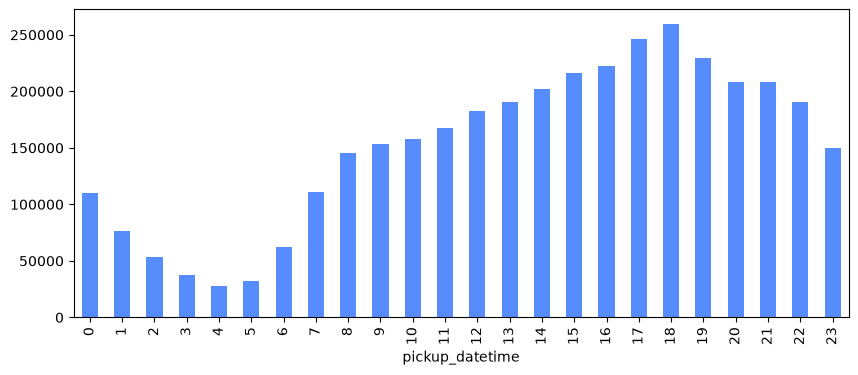

In [7]:
hourly = yellow_1_new["pickup_datetime"].dt.hour.value_counts().sort_index()

hourly.plot.bar(figsize=(10, 4))

<Axes: ylabel='Frequency'>

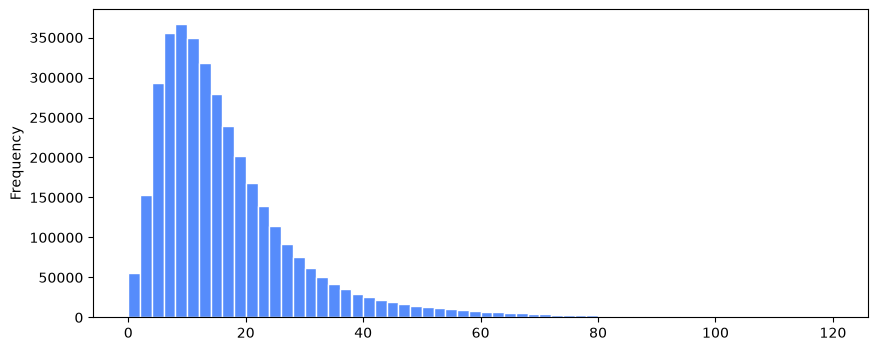

In [8]:
duration_for_plot = yellow_1_new.loc[yellow_1_new["duration_min"].between(0, 120, inclusive="right"), "duration_min"]
duration_for_plot.plot.hist(bins = 60, figsize = (10, 4), edgecolor="white")

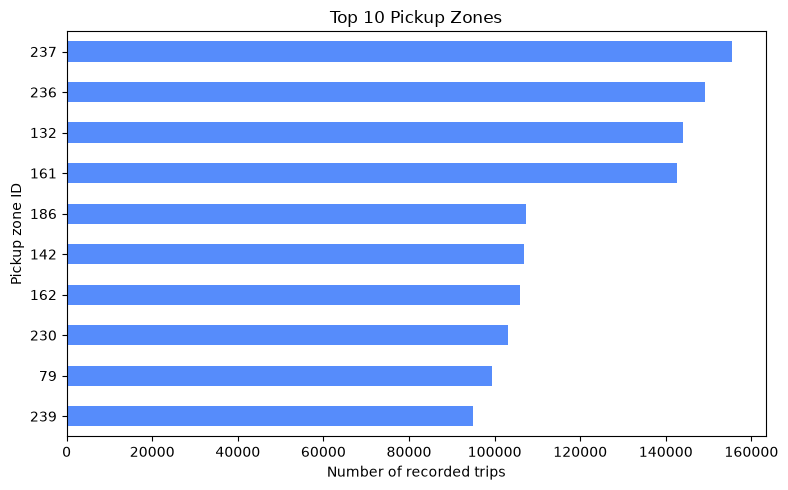

In [9]:
top_zones = (yellow_1_new["pulocationid"].value_counts().head(10).sort_values())

top_zones.index = top_zones.index.astype(str)
top_zones.plot.barh(figsize=(8, 5))

plt.title("Top 10 Pickup Zones")
plt.xlabel("Number of recorded trips")
plt.ylabel("Pickup zone ID")
plt.tight_layout()
plt.show()

In [10]:
ml_data = yellow_1_new.loc[
    yellow_1_new["duration_min"].between(1, 120),
    ["pickup_datetime", "duration_min"],
].copy()

ml_data = ml_data.dropna()

ml_data["pickup_hour"] = ml_data["pickup_datetime"].dt.hour
ml_data["weekday"] = ml_data["pickup_datetime"].dt.dayofweek
# Monday = 0, Sunday = 6

# Train on earlier dates; test on later dates
train = ml_data.loc[
    ml_data["pickup_datetime"] < "2026-01-25"
]

test = ml_data.loc[
    ml_data["pickup_datetime"] >= "2026-01-25"
]

# Keep the pilot lightweight
train = train.sample(n=min(100_000, len(train)), random_state=42)
test = test.sample(n=min(30_000, len(test)), random_state=42)

features = ["pickup_hour", "weekday"]

X_train = train[features]
y_train = train["duration_min"]

X_test = test[features]
y_test = test["duration_min"]

# Baseline: always predict the training median
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

# Simple ML model
model = DecisionTreeRegressor(max_depth=4, random_state=42)
model.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
predictions = model.predict(X_test)

print("Training rows:", len(train))
print("Test rows:", len(test))

print(
    "Baseline MAE:",
    round(mean_absolute_error(y_test, baseline_predictions), 2),
    "minutes",
)

print(
    "Decision tree MAE:",
    round(mean_absolute_error(y_test, predictions), 2),
    "minutes",
)

C:\Users\winston53\AppData\Local\Temp\ipykernel_7676\1964557459.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ml_data["weekday"] = ml_data["pickup_datetime"].dt.dayofweek


Training rows: 100000
Test rows: 30000
Baseline MAE: 9.94 minutes
Decision tree MAE: 9.67 minutes
